# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [3]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [4]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [5]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

def parse_dates(series, min_success_rate=0.95):
    # Convertir les dates
    converted = pd.to_datetime(
        series, format='mixed', dayfirst=True, errors='coerce'
    )

    # Calculer les statistiques
    n_total = len(series)
    n_already_missing = int(series.isna().sum())
    n_failed = int(converted.isna().sum() - n_already_missing)

    n_to_convert = n_total - n_already_missing
    success_rate = (
        (n_to_convert - n_failed) / n_to_convert
        if n_to_convert > 0 else 0
    )

    # Créer le rapport
    report = {
        'n_total': n_total,
        'n_already_missing': n_already_missing,
        'n_failed': n_failed,
        'success_rate': round(success_rate, 4),
        'min_date': converted.min(),
        'max_date': converted.max()
    }

    # Vérifier le seuil de réussite
    if success_rate < min_success_rate:
        raise ValueError(
            f"Taux de réussite insuffisant : {success_rate:.2%}"
        )

    return converted, report


order_dates, report = parse_dates(raw_sales['date_commande'])
print(report)

{'n_total': 17609, 'n_already_missing': 350, 'n_failed': 0, 'success_rate': 1.0, 'min_date': Timestamp('2023-01-01 00:00:00'), 'max_date': Timestamp('2024-12-30 17:10:00')}


---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [6]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-02-11 00:00:00,2024,2,Sunday,6,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [7]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [8]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).
# Q2. Ajouter les quatre variables temporelles

# 1. Période de la journée
# Matin avant 12h, après-midi de 12h à 17h, soir à partir de 18h
sales['periode_journee'] = pd.cut(
    sales['heure'],
    bins=[-1, 11, 17, 23],
    labels=['matin', 'apres-midi', 'soir']
)

# 2. Fin de mois : les trois derniers jours
sales['est_fin_de_mois'] = (
    sales['date_commande'].dt.days_in_month
    - sales['date_commande'].dt.day < 3
)

# 3. Nombre de jours depuis la première commande
premiere_commande = sales['date_commande'].min()

sales['jours_depuis_debut'] = (
    sales['date_commande'] - premiere_commande
).dt.days

# 4. Ancienneté du client au moment de la commande
clients = pd.read_csv(RAW_DIR / 'clients.csv')

clients['date_inscription'] = pd.to_datetime(
    clients['date_inscription'],
    errors='coerce'
)

sales = sales.merge(
    clients[['id_client', 'date_inscription']],
    on='id_client',
    how='left'
)

sales['anciennete_client_jours'] = (
    sales['date_commande'] - sales['date_inscription']
).dt.days

# Afficher les résultats
display(sales[
    ['periode_journee', 'est_fin_de_mois',
     'jours_depuis_debut', 'anciennete_client_jours']
].head())
# TODO

,periode_journee,est_fin_de_mois,jours_depuis_debut,anciennete_client_jours
0,soir,False,382,1005
1,matin,False,372,-42
2,matin,False,104,1511
3,matin,False,675,1985
4,matin,False,406,1135


In [9]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.
# 1. Montant moyen des commandes : semaine VS week-end
print("=== Montant moyen selon le week-end ===")
print(
    sales.groupby('est_weekend')['montant']
    .mean()
    .round(2)
)

# 2. Montant moyen selon le jour de la semaine
print("\n=== Montant moyen selon le jour ===")

ordre_jours = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

montant_par_jour = (
    sales.groupby('nom_jour')['montant']
    .mean()
    .reindex(ordre_jours)
    .round(2)
)

print(montant_par_jour)

# 3. Comparer automatiquement les résultats
moyenne_weekend = sales.loc[sales['est_weekend'], 'montant'].mean()
moyenne_semaine = sales.loc[~sales['est_weekend'], 'montant'].mean()

if moyenne_weekend > moyenne_semaine:
    print("\nConclusion : le montant moyen est plus élevé le week-end.")
elif moyenne_weekend < moyenne_semaine:
    print("\nConclusion : le montant moyen est plus élevé en semaine.")
else:
    print("\nConclusion : le montant moyen est identique.")

# Commentaire :
# Cette analyse permet de comparer les dépenses moyennes selon le jour.
# Les différences observées peuvent indiquer des habitudes d'achat.
# Attention : un montant moyen plus élevé ne signifie pas forcément
# un chiffre d'affaires total plus élevé, car le nombre de commandes
# peut varier selon les jours.
# TODO

=== Montant moyen selon le week-end ===
est_weekend
False    2093.99
True     3602.39
Name: montant, dtype: float64

=== Montant moyen selon le jour ===
nom_jour
Monday       1738.36
Tuesday      2042.24
Wednesday    2163.77
Thursday     2208.00
Friday       2324.70
Saturday     2830.33
Sunday       4351.31
Name: montant, dtype: float64

Conclusion : le montant moyen est plus élevé le week-end.


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [10]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [11]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


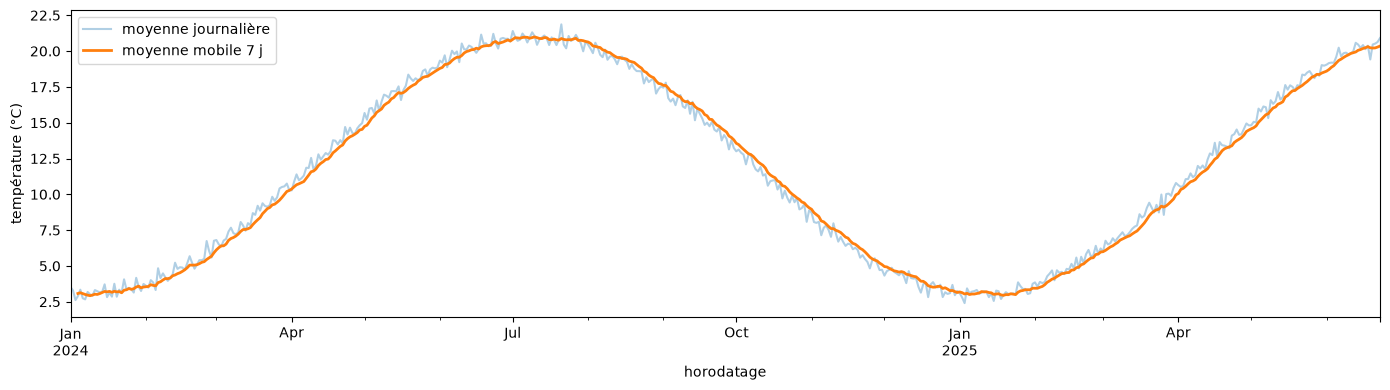

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [14]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.
# 1. Sélectionner les données du capteur CAP-B
sensor_b = (
    sensors[sensors['id_capteur'] == 'CAP-B']
    .set_index('horodatage')
    .sort_index()
)

# 2. Créer une plage horaire complète
heures = pd.date_range(
    start=sensor_b.index.min(),
    end=sensor_b.index.max(),
    freq='h'
)

# 3. Réindexer : les heures sans mesure deviennent des NaN
sensor_b_complet = sensor_b.reindex(heures)

# 4. Identifier les heures sans aucune mesure
manquantes = sensor_b_complet['id_capteur'].isna()

# 5. Regrouper les heures manquantes consécutives
groupes = (manquantes != manquantes.shift()).cumsum()

# 6. Détecter les pannes de plus de 24 heures
pannes = []

for _, groupe in manquantes.groupby(groupes):
    if groupe.iloc[0] and len(groupe) > 24:
        pannes.append({
            'debut': groupe.index.min(),
            'fin': groupe.index.max(),
            'duree_heures': len(groupe)
        })

# 7. Afficher les résultats
pannes_df = pd.DataFrame(pannes)

print("Pannes détectées :")
display(pannes_df)
# TODO

Pannes détectées :


,debut,fin,duree_heures
0,2024-06-03,2024-06-13 23:00:00,264


In [15]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.
# 1. Sélectionner les mesures de CAP-C
sensor_c = (
    sensors[sensors['id_capteur'] == 'CAP-C']
    .sort_values('horodatage')
    .copy()
)

# 2. Repérer les changements de température
# ou les interruptions entre deux relevés horaires
changements = (
    sensor_c['temperature_c'].ne(sensor_c['temperature_c'].shift())
    | sensor_c['horodatage'].diff().ne(pd.Timedelta(hours=1))
)

# 3. Identifier les groupes de valeurs consécutives identiques
sensor_c['groupe'] = changements.cumsum()

# 4. Détecter les périodes de plus de 24 relevés constants
periodes = []

for _, groupe in sensor_c.groupby('groupe'):
    if len(groupe) > 24 and groupe['temperature_c'].notna().all():
        periodes.append({
            'debut': groupe['horodatage'].min(),
            'fin': groupe['horodatage'].max(),
            'temperature': groupe['temperature_c'].iloc[0],
            'nombre_releves': len(groupe)
        })

# 5. Afficher les résultats
periodes_df = pd.DataFrame(periodes)

print("Périodes où CAP-C est bloqué :")
display(periodes_df)
# TODO

Périodes où CAP-C est bloqué :


,debut,fin,temperature,nombre_releves
0,2024-09-10 01:00:00,2024-09-12 05:00:00,17.4,53
1,2024-09-12 07:00:00,2024-09-14 09:00:00,17.4,51


=== Chiffre d'affaires hebdomadaire ===


date_commande
2023-01-01     27592.60
2023-01-08    183352.61
2023-01-15    212497.50
2023-01-22    642307.62
2023-01-29    948258.62
Freq: W-SUN, Name: montant, dtype: float64


=== Chiffre d'affaires mensuel ===


date_commande
2023-01-01    2075715.57
2023-02-01    1404553.00
2023-03-01    3012146.69
2023-04-01    1622135.54
2023-05-01    1278272.47
2023-06-01    1119699.53
2023-07-01    2677192.18
2023-08-01    2078376.64
2023-09-01    2407398.15
2023-10-01     828696.86
2023-11-01    2300027.42
2023-12-01    1090197.77
2024-01-01    2218776.68
2024-02-01    1457403.62
2024-03-01    1451364.67
2024-04-01    1955423.98
2024-05-01    2668359.55
2024-06-01     924575.13
2024-07-01    1035443.56
2024-08-01    2766742.44
2024-09-01     990814.16
2024-10-01    1716070.22
2024-11-01    1158470.76
2024-12-01    2477989.53
Freq: MS, Name: montant, dtype: float64

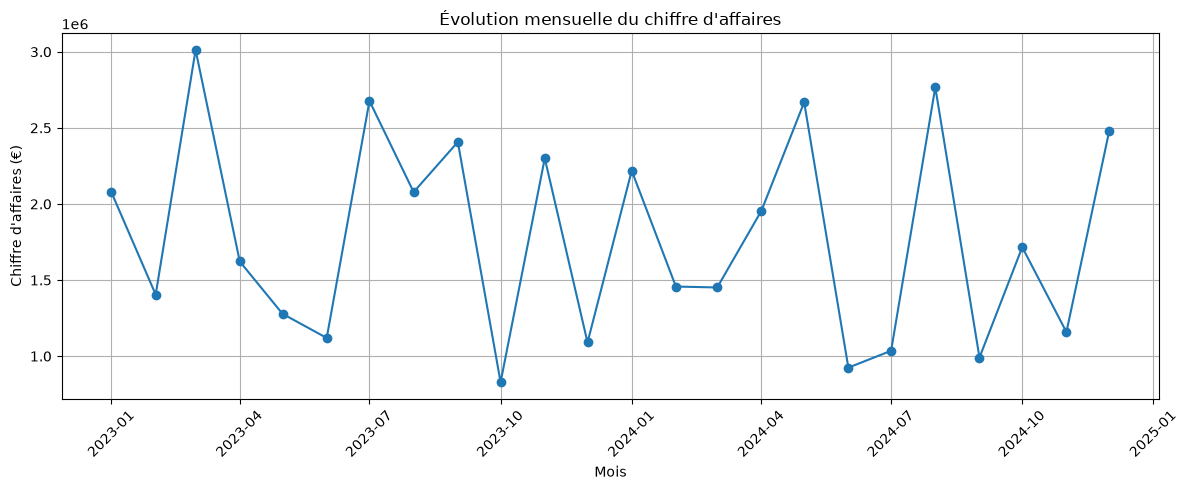

In [16]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.
# 1. Préparer les données
ventes = sales.copy()
ventes['date_commande'] = pd.to_datetime(ventes['date_commande'])
ventes = ventes.set_index('date_commande').sort_index()

# 2. Chiffre d'affaires par semaine
ca_hebdomadaire = ventes['montant'].resample('W').sum()

print("=== Chiffre d'affaires hebdomadaire ===")
display(ca_hebdomadaire.head())

# 3. Chiffre d'affaires par mois
ca_mensuel = ventes['montant'].resample('MS').sum()

print("\n=== Chiffre d'affaires mensuel ===")
display(ca_mensuel)

# 4. Tracer l'évolution mensuelle du chiffre d'affaires
plt.figure(figsize=(12, 5))
plt.plot(ca_mensuel.index, ca_mensuel.values, marker='o')

plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (€)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Commentaire :
# On cherche à observer une saisonnalité des ventes.
# Le jeu de données a été conçu avec une hausse des ventes
# en novembre et décembre et une baisse en août.
# Le graphique permet de vérifier si ces tendances apparaissent
# dans le chiffre d'affaires mensuel.
# TODO

---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.